# Diabetes Predictive Modeling

## Nonlinear Classification

Is there a nonlinear relationship between any health indicators and having a diabetes diagnosis?

2015 CDC Survey Data (balanced and clean)

In [ ]:
%%capture
!conda install -c conda-forge py-xgboost -y
!conda install -c conda-forge python-graphviz -y

In [28]:
from xgboost import XGBClassifier
from xgboost import plot_importance
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from xgboost import plot_tree
import graphviz

In [30]:
diabetes = pd.read_csv("diabetes_binary_5050split_health_indicators_BRFSS2015.csv")

diabetes_0 = diabetes[diabetes["Diabetes_binary"] == 0]
# subset containing surveys of people with diabetes/prediabetes
diabetes_1 = diabetes[diabetes["Diabetes_binary"] == 1]

diabetes_train_0 = diabetes_0.iloc[: 25000, 1:]
diabetes_label_0 = diabetes_0.iloc[: 25000, 0]

diabetes_train_1 = diabetes_1.iloc[: 25000, 1:]
diabetes_label_1 = diabetes_1.iloc[: 25000, 0]

diabetes_train_data = pd.concat([diabetes_train_0, diabetes_train_1], axis=0)
diabetes_train_labels = pd.concat([diabetes_label_0, diabetes_label_1], axis=0)

test_data_0 = diabetes_0.iloc[25000 :, 1:]
test_label_0 = diabetes_0.iloc[25000 :, 0]

test_data_1 = diabetes_1.iloc[25000 :, 1:]
test_label_1 = diabetes_1.iloc[25000 :, 0]

diabetes_test_data = pd.concat([test_data_0, test_data_1], axis=0)
diabetes_test_labels = pd.concat([test_label_0, test_label_1], axis=0)

#Shuffle, so all zeros don't come first and are followed by all ones
diabetes_train_data = diabetes_train_data.sample(frac=1, random_state=42)
diabetes_train_labels = diabetes_train_labels.reindex(diabetes_train_data.index)

diabetes_test_data = diabetes_test_data.sample(frac=1, random_state=42)
diabetes_test_labels = diabetes_test_labels.reindex(diabetes_test_data.index)

In [32]:
model = XGBClassifier(n_estimators=400, learning_rate=0.2, max_depth=3, random_state=42)
model.fit(diabetes_train_data, diabetes_train_labels)

pred_diabetes_train = model.predict(diabetes_train_data)
pred_diabetes_test = model.predict(diabetes_test_data)

cm = confusion_matrix(diabetes_test_labels, pred_diabetes_test) 
print(cm)

print(classification_report(
    diabetes_test_labels,
    pred_diabetes_test,
    target_names=["No diabetes", "Diabetes/prediabetes"]
))

print("Training accuracy:",
      accuracy_score(diabetes_train_labels, pred_diabetes_train))

print("Testing accuracy:",
      accuracy_score(diabetes_test_labels, pred_diabetes_test))

[[7242 3104]
 [1943 8403]]
                      precision    recall  f1-score   support

         No diabetes       0.79      0.70      0.74     10346
Diabetes/prediabetes       0.73      0.81      0.77     10346

            accuracy                           0.76     20692
           macro avg       0.76      0.76      0.76     20692
        weighted avg       0.76      0.76      0.76     20692

Training accuracy: 0.76346
Testing accuracy: 0.7560893098782138


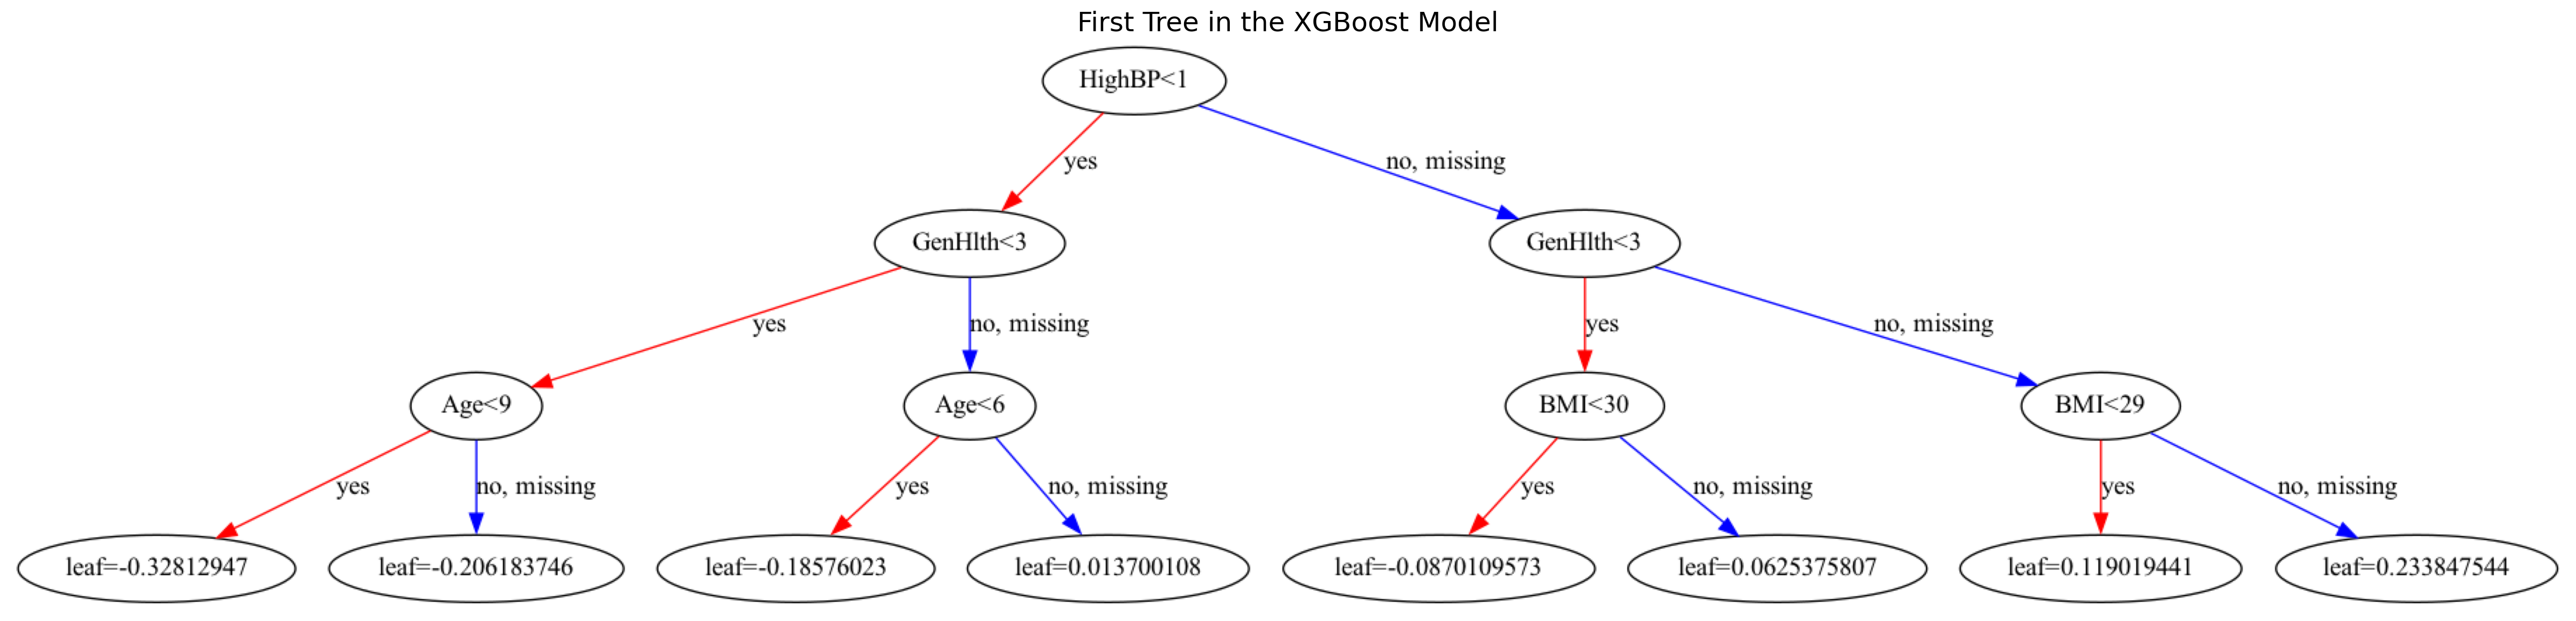

In [46]:
fig, ax = plt.subplots(figsize=(24, 10), dpi=200)

plot_tree(model, tree_idx=0, ax=ax)
ax.set_title("First Tree in the XGBoost Model", fontsize=18)

plt.tight_layout()
plt.savefig("xgboost_tree.png", dpi=300, bbox_inches="tight")
plt.show()

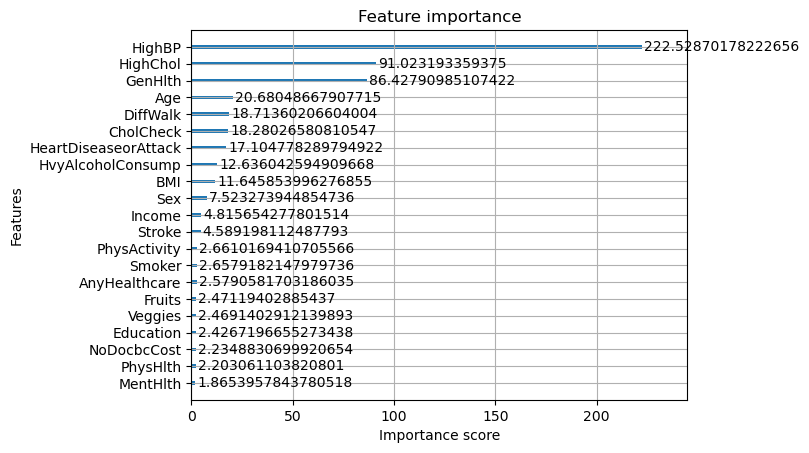

<Figure size 900x600 with 0 Axes>

In [56]:
plot_importance(model, importance_type="gain")
plt.figure(figsize=(9,6))
plt.tight_layout()
plt.show()